In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\asus\myvenv310\Scripts\python.exe
3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]


In [45]:
import neo4j
import numpy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
from neo4j import GraphDatabase
from getpass import getpass

# Konfigurasi koneksi Neo4j
URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

print("Konfigurasi koneksi berhasil dibuat.")

Konfigurasi koneksi berhasil dibuat.


In [8]:
try:
    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil!")
except Exception as e:
    print("Koneksi gagal:", e)

Koneksi ke Neo4j berhasil!


C:\Users\asus\AppData\Local\Temp\ipykernel_31460\4010380769.py:2: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


## Pemeriksaan Database

In [9]:
query_nodes = """
MATCH (n)
RETURN labels(n) AS jenis_node, count(n) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_nodes)
    nodes_df = pd.DataFrame([record.data() for record in result])

display(nodes_df)

,jenis_node,jumlah
0,"[Person, Actor]",37014
1,[Movie],9742
2,"[Person, Producer]",6425
3,"[Person, Writer]",4600
4,"[Person, Director]",1366
5,"[Person, Director, Writer]",1256
6,"[Person, Director, Writer, Producer]",661
7,[User],610
8,"[Person, Writer, Producer]",484
9,"[Person, Actor, Writer]",452


In [10]:
query_relationships = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_relationships)
    relationships_df = pd.DataFrame(
        [record.data() for record in result]
    )

display(relationships_df)

,jenis_relasi,jumlah
0,RATED,100836
1,ACTS_IN,93017
2,HAS,22084
3,PRODUCED,20800
4,WRITED,15952
5,SIMILARITY,12183
6,DIRECTED,10498


In [11]:
query_ratings = """
MATCH (u:User)-[r:RATED]->(m:Movie)
RETURN count(r) AS total_rating,
       count(DISTINCT u) AS total_user,
       count(DISTINCT m) AS total_movie
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_ratings)
    rating_summary = pd.DataFrame(
        [record.data() for record in result]
    )

display(rating_summary)

,total_rating,total_user,total_movie
0,100836,610,9724


## Load Dataset MovieLens

Pada tahap ini dilakukan pengambilan data rating dari database Neo4j menggunakan Cypher Query. Data yang diambil meliputi userId, movieId, dan rating.

Data kemudian disimpan dalam Pandas DataFrame untuk digunakan pada tahap eksplorasi data, preprocessing, dan perhitungan User-Based Collaborative Filtering.

In [12]:
query_load = """
MATCH (u:User)-[r:RATED]->(m:Movie)
RETURN
    u.userId AS userId,
    m.movieId AS movieId,
    r.rating AS rating
ORDER BY userId, movieId
"""

with driver.session(database="neo4j") as session:
    result = session.run(query_load)
    records = [record.data() for record in result]

df = pd.DataFrame(records)

print("Data berhasil diambil dari Neo4j!")
print("Jumlah baris dan kolom:", df.shape)

display(df.head(10))

Data berhasil diambil dari Neo4j!
Jumlah baris dan kolom: (100836, 3)


,userId,movieId,rating
0,1,1,4.0
1,1,1009,3.0
2,1,101,5.0
3,1,1023,5.0
4,1,1024,5.0
5,1,1025,5.0
6,1,1029,5.0
7,1,1030,3.0
8,1,1031,5.0
9,1,1032,5.0


In [13]:
print("Informasi Dataset:")
df.info()

print("\nStatistik Deskriptif:")
display(df.describe())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 3 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   userId   100836 non-null  object
 1   movieId  100836 non-null  object
 2   rating   100836 non-null  object
dtypes: object(3)
memory usage: 2.3+ MB

Statistik Deskriptif:


,userId,movieId,rating
count,100836,100836,100836
unique,610,9724,10
top,414,356,4.0
freq,2698,329,26818


In [14]:
print("Jumlah User       :", df["userId"].nunique())
print("Jumlah Movie      :", df["movieId"].nunique())
print("Jumlah Rating     :", len(df))
print("Jumlah User-Movie :", df[["userId", "movieId"]].drop_duplicates().shape[0])

Jumlah User       : 610
Jumlah Movie      : 9724
Jumlah Rating     : 100836
Jumlah User-Movie : 100836


## Exploratory Data Analysis (EDA)

In [ ]:
df["userId"] = pd.to_numeric(df["userId"], errors="coerce")
df["movieId"] = pd.to_numeric(df["movieId"], errors="coerce")
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

df["userId"] = df["userId"].astype("Int64")
df["movieId"] = df["movieId"].astype("Int64")

print("Tipe data setelah konversi:")
print(df.dtypes)

display(df.head())

Tipe data setelah konversi:
userId       Int64
movieId      Int64
rating     float64
dtype: object


,userId,movieId,rating
0,1,1,4.0
1,1,1009,3.0
2,1,101,5.0
3,1,1023,5.0
4,1,1024,5.0


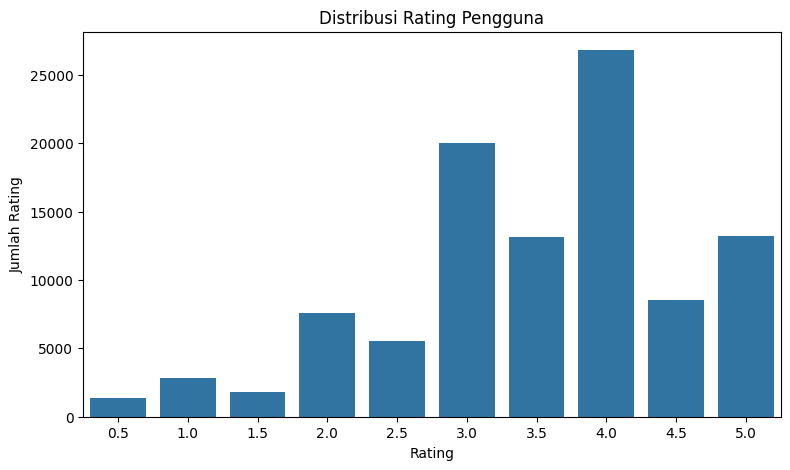

In [16]:
rating_counts = df["rating"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribusi Rating Pengguna")
plt.xlabel("Rating")
plt.ylabel("Jumlah Rating")
plt.show()

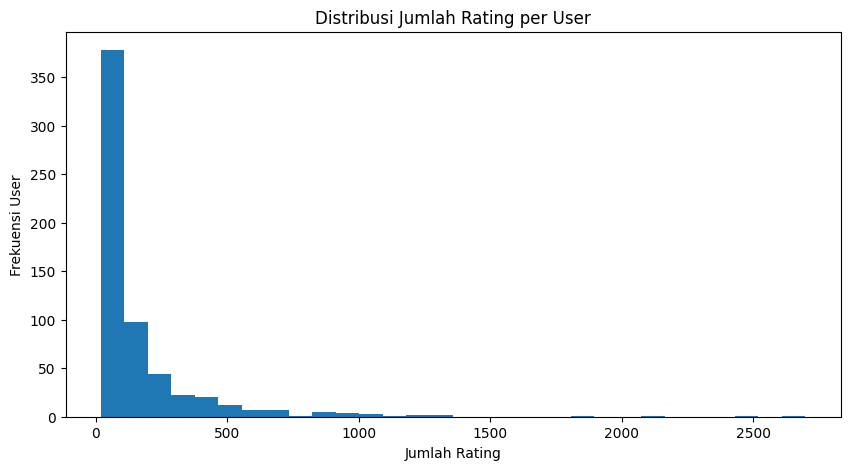

Rata-rata rating per user: 165.3
Minimum rating per user: 20
Maksimum rating per user: 2698


In [17]:
ratings_per_user = df.groupby("userId").size()

plt.figure(figsize=(10, 5))
plt.hist(ratings_per_user, bins=30)

plt.title("Distribusi Jumlah Rating per User")
plt.xlabel("Jumlah Rating")
plt.ylabel("Frekuensi User")
plt.show()

print("Rata-rata rating per user:", round(ratings_per_user.mean(), 2))
print("Minimum rating per user:", ratings_per_user.min())
print("Maksimum rating per user:", ratings_per_user.max())

## Data Preprocessing


In [18]:
df_raw = df.copy()
df = df_raw.copy()

print("Salinan dataset berhasil dibuat.")
print("Jumlah data awal:", len(df))

Salinan dataset berhasil dibuat.
Jumlah data awal: 100836


In [19]:
missing_check = pd.DataFrame({
    "Jumlah Missing": df.isnull().sum(),
    "Persentase (%)": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_check)

,Jumlah Missing,Persentase (%)
userId,0,0.0
movieId,0,0.0
rating,0,0.0


In [20]:
duplicate_all = df.duplicated().sum()

print("Jumlah duplikasi seluruh baris:", duplicate_all)

Jumlah duplikasi seluruh baris: 0


In [21]:
duplicate_pair = df.duplicated(
    subset=["userId", "movieId"]
).sum()

print("Jumlah duplikasi pasangan User-Movie:", duplicate_pair)

Jumlah duplikasi pasangan User-Movie: 0


In [22]:
print("Rating minimum:", df["rating"].min())
print("Rating maksimum:", df["rating"].max())

valid_rating = (
    df["rating"].between(0.5, 5.0) &
    (df["rating"] * 2).mod(1).eq(0)
)

print("Rating valid:", valid_rating.sum())
print("Rating tidak valid:", (~valid_rating).sum())

Rating minimum: 0.5
Rating maksimum: 5.0
Rating valid: 100836
Rating tidak valid: 0


In [23]:
quality_summary = pd.DataFrame({
    "Pemeriksaan": [
        "Missing Values",
        "Duplicate Records",
        "Duplicate User-Movie",
        "Invalid Rating"
    ],
    "Jumlah": [
        df.isnull().sum().sum(),
        duplicate_all,
        duplicate_pair,
        (~valid_rating).sum()
    ]
})

display(quality_summary)

,Pemeriksaan,Jumlah
0,Missing Values,0
1,Duplicate Records,0
2,Duplicate User-Movie,0
3,Invalid Rating,0


Berdasarkan hasil pemeriksaan, dataset tidak memiliki missing values, duplikasi data, maupun nilai rating di luar rentang yang ditentukan. Oleh karena itu, tidak diperlukan proses imputasi atau penghapusan data.

## **User-Based Filtering - Weighted**


## 1. Pembentukan User-Rating Dictionary

Pada tahap ini, data rating dikelompokkan berdasarkan pengguna menggunakan struktur dictionary. Setiap pengguna memiliki pasangan movieId dan rating yang telah diberikan.

Struktur ini digunakan sebagai dasar untuk menghitung Weighted Cosine Similarity antar pengguna.

In [25]:
from collections import defaultdict

# Mengelompokkan rating berdasarkan user
user_ratings = defaultdict(dict)

for row in df.itertuples(index=False):
    user = str(row.userId)
    movie = str(row.movieId)
    rating = float(row.rating)

    user_ratings[user][movie] = rating

print("Jumlah user:", len(user_ratings))
print("Jumlah rating User 1:", len(user_ratings["1"]))

print("\nContoh rating User 1:")
display(pd.DataFrame(
    list(user_ratings["1"].items()),
    columns=["movieId", "rating"]
).head(10))

Jumlah user: 610
Jumlah rating User 1: 232

Contoh rating User 1:


,movieId,rating
0,1,4.0
1,1009,3.0
2,101,5.0
3,1023,5.0
4,1024,5.0
5,1025,5.0
6,1029,5.0
7,1030,3.0
8,1031,5.0
9,1032,5.0


## 2. Perhitungan Weighted Cosine Similarity

Weighted Cosine Similarity digunakan untuk mengukur tingkat kemiripan antar pengguna berdasarkan nilai rating aktual yang diberikan terhadap film yang sama-sama dinilai.

### 2.1 Identifikasi Common Movies

Common Movies merupakan film yang mendapatkan rating dari kedua pengguna. Perhitungan similarity hanya dilakukan menggunakan film yang sama-sama dinilai.

In [26]:
# Menentukan dua user yang akan dibandingkan
user_a = "1"
user_b = "77"

ratings_a = user_ratings[user_a]
ratings_b = user_ratings[user_b]

# Mencari film yang sama-sama dinilai
common_movies = ratings_a.keys() & ratings_b.keys()

print("User A:", user_a)
print("User B:", user_b)
print("Jumlah Common Movies:", len(common_movies))

# Menampilkan rating kedua user pada film yang sama
comparison_df = pd.DataFrame({
    "movieId": list(common_movies),
    "rating_user_A": [ratings_a[m] for m in common_movies],
    "rating_user_B": [ratings_b[m] for m in common_movies]
})

comparison_df = comparison_df.sort_values("movieId")

display(comparison_df.head(15))

User A: 1
User B: 77
Jumlah Common Movies: 6


,movieId,rating_user_A,rating_user_B
5,1196,5.0,5.0
3,1198,5.0,5.0
1,1210,5.0,5.0
4,2571,5.0,5.0
0,260,5.0,5.0
2,3578,5.0,5.0


### 2.2 Memeriksa minimum common movies

Pasangan user hanya dihitung apabila memiliki minimal 5 film yang sama-sama dinilai.

In [27]:
MIN_COMMON = 5

if len(common_movies) >= MIN_COMMON:
    print("Pasangan user memenuhi syarat.")
else:
    print("Pasangan user tidak memenuhi syarat.")

Pasangan user memenuhi syarat.


### 2.3 Menghitung komponen cosine similarity

In [28]:
import math

# Dot product
dot_product = sum(
    ratings_a[m] * ratings_b[m]
    for m in common_movies
)

# Norm masing-masing user
norm_a = math.sqrt(
    sum(ratings_a[m] ** 2 for m in common_movies)
)

norm_b = math.sqrt(
    sum(ratings_b[m] ** 2 for m in common_movies)
)

# Cosine similarity
similarity = dot_product / (norm_a * norm_b)

print("Dot Product :", round(dot_product, 4))
print("Norm User A :", round(norm_a, 4))
print("Norm User B :", round(norm_b, 4))
print("Similarity  :", round(similarity, 4))

Dot Product : 150.0
Norm User A : 12.2474
Norm User B : 12.2474
Similarity  : 1.0


## 3. Perhitungan Weighted Cosine Similarity Seluruh User

Pada tahap ini dilakukan perhitungan cosine similarity terhadap setiap pasangan pengguna. Perhitungan hanya dilakukan berdasarkan film yang sama-sama mendapatkan rating dari kedua pengguna.

Pasangan pengguna dengan jumlah common movies kurang dari 5 tidak akan diproses. Hasil similarity kemudian disimpan sebagai kandidat nearest neighbors untuk setiap pengguna.

In [29]:
# Parameter algoritma
K = 20
MIN_COMMON = 5

# Menyimpan kandidat neighbors setiap user
neighbors = defaultdict(list)

# Mengurutkan user berdasarkan ID
user_ids = sorted(user_ratings, key=int)

total_pairs = len(user_ids) * (len(user_ids) - 1) // 2
eligible_pairs = 0

print("Jumlah user:", len(user_ids))
print("Total pasangan user yang akan dibandingkan:", total_pairs)

# Membandingkan setiap pasangan user
for i, user_a in enumerate(user_ids):
    ratings_a = user_ratings[user_a]

    for user_b in user_ids[i + 1:]:
        ratings_b = user_ratings[user_b]

        # Mencari film yang sama-sama dinilai
        common = ratings_a.keys() & ratings_b.keys()

        # Memeriksa minimum common movies
        if len(common) < MIN_COMMON:
            continue

        # Menghitung dot product
        dot_product = sum(
            ratings_a[movie] * ratings_b[movie]
            for movie in common
        )

        # Menghitung norm
        norm_a = math.sqrt(
            sum(ratings_a[movie] ** 2 for movie in common)
        )

        norm_b = math.sqrt(
            sum(ratings_b[movie] ** 2 for movie in common)
        )

        if norm_a == 0 or norm_b == 0:
            continue

        # Menghitung cosine similarity
        pair_similarity = dot_product / (norm_a * norm_b)

        # Menyimpan hasil untuk kedua arah
        neighbors[user_a].append(
            (pair_similarity, len(common), user_b)
        )

        neighbors[user_b].append(
            (pair_similarity, len(common), user_a)
        )

        eligible_pairs += 1

print("\nPerhitungan selesai!")
print("Total pasangan yang memenuhi syarat:", eligible_pairs)
print("Total user yang memiliki kandidat neighbor:", len(neighbors))

Jumlah user: 610
Total pasangan user yang akan dibandingkan: 185745

Perhitungan selesai!
Total pasangan yang memenuhi syarat: 108202
Total user yang memiliki kandidat neighbor: 610


In [30]:
# Mengambil kandidat similarity User 1
user_1_candidates = sorted(
    neighbors["1"],
    key=lambda item: (
        -item[0],
        -item[1],
        int(item[2])
    )
)

candidate_df = pd.DataFrame(
    user_1_candidates,
    columns=[
        "similarity",
        "commonMovies",
        "neighborId"
    ]
)

display(candidate_df.head(20))

,similarity,commonMovies,neighborId
0,1.000000,6,77
1,0.999193,6,511
2,0.998633,5,366
3,0.998060,6,114
4,0.997825,5,65
5,0.996963,7,49
6,0.996546,5,258
7,0.996287,10,180
8,0.996205,6,523
9,0.995739,5,9


## 4. Penentuan Top-20 Nearest Neighbors

Setelah seluruh kandidat similarity diperoleh, setiap pengguna akan dipilihkan maksimal 20 pengguna dengan nilai kemiripan tertinggi.

Pengurutan dilakukan berdasarkan nilai similarity secara menurun, jumlah common movies secara menurun, dan userId secara menaik sebagai kriteria tambahan ketika terdapat nilai yang sama.

In [32]:
# Memilih Top-20 neighbors setiap user
top_neighbors = defaultdict(list)

for user in user_ids:
    top = sorted(
        neighbors[user],
        key=lambda item: (
            -item[0],
            -item[1],
            int(item[2])
        )
    )[:K]

    top_neighbors[user] = top

# Mengubah hasil menjadi DataFrame
similarity_rows = []

for user, neighbor_list in top_neighbors.items():
    for similarity, common_count, neighbor in neighbor_list:
        similarity_rows.append({
            "source": user,
            "target": neighbor,
            "similarity": similarity,
            "commonMovies": common_count
        })

similarity_df = pd.DataFrame(similarity_rows)

print("Jumlah user:", len(top_neighbors))
print("Jumlah relationship similarity:", len(similarity_df))

print("\nContoh Top-20 Neighbors User 1:")
display(
    similarity_df[
        similarity_df["source"] == "1"
    ].head(20)
)

Jumlah user: 610
Jumlah relationship similarity: 12183

Contoh Top-20 Neighbors User 1:


,source,target,similarity,commonMovies
0,1,77,1.000000,6
1,1,511,0.999193,6
2,1,366,0.998633,5
3,1,114,0.998060,6
4,1,65,0.997825,5
5,1,49,0.996963,7
6,1,258,0.996546,5
7,1,180,0.996287,10
8,1,523,0.996205,6
9,1,9,0.995739,5


Berdasarkan perhitungan Weighted Cosine Similarity terhadap 610 pengguna, diperoleh 185.745 pasangan pengguna yang dibandingkan. Sebanyak 108.202 pasangan memenuhi kriteria minimum 5 common movies.

Selanjutnya, dipilih maksimal 20 nearest neighbors untuk setiap pengguna sehingga menghasilkan 12.183 relationship similarity. Hasil perhitungan menunjukkan bahwa User 77 merupakan pengguna paling mirip dengan User 1, dengan nilai similarity sebesar 1.000000 berdasarkan 6 film yang sama-sama dinilai.

## Penyimpanan Hasil Similarity ke Neo4j

Hasil perhitungan Top-20 Nearest Neighbors disimpan kembali ke database Neo4j sebagai relationship SIMILARITY. Setiap relationship memiliki properti similarity, commonMovies, dan method.

In [33]:
STORE = """
UNWIND $rows AS row
MATCH (a:User)
WHERE toString(a.userId) = row.source
MATCH (b:User)
WHERE toString(b.userId) = row.target
MERGE (a)-[s:SIMILARITY]->(b)
SET s.value = row.similarity,
    s.commonMovies = row.commonMovies,
    s.method = 'cosine_weighted_ratings'
"""

CLEAR_OWN_KNN = """
MATCH (:User)-[s:SIMILARITY]->(:User)
WHERE s.method = 'cosine_weighted_ratings'
DELETE s
"""

In [34]:
rows = similarity_df.to_dict("records")

with driver.session(database="neo4j") as session:
    with session.begin_transaction() as tx:

        # Hapus hanya relationship Weighted sebelumnya
        tx.run(CLEAR_OWN_KNN).consume()

        # Simpan hasil secara bertahap
        for start in range(0, len(rows), 1000):
            tx.run(
                STORE,
                rows=rows[start:start + 1000]
            ).consume()

        tx.commit()

print("Hasil Weighted Similarity berhasil disimpan ke Neo4j!")
print("Total relationship:", len(rows))

Hasil Weighted Similarity berhasil disimpan ke Neo4j!
Total relationship: 12183


## Evaluasi

In [38]:
import numpy as np
import pandas as pd
from collections import defaultdict

K = 20
MIN_COMMON = 5
TOP_N = 10
TEST_RATIO = 0.20
RELEVANT_RATING = 4.0
SEED = 42

rng = np.random.default_rng(SEED)

train = defaultdict(dict)
test = defaultdict(dict)

for user, group in df.groupby("userId", sort=True):

    items = list(
        group[["movieId", "rating"]].itertuples(
            index=False, name=None
        )
    )

    rng.shuffle(items)

    if len(items) < 2:
        train[str(user)] = {
            str(movie): float(rating)
            for movie, rating in items
        }
        continue

    n_test = max(1, round(len(items) * TEST_RATIO))
    n_test = min(n_test, len(items) - 1)

    test[str(user)] = {
        str(movie): float(rating)
        for movie, rating in items[:n_test]
    }

    train[str(user)] = {
        str(movie): float(rating)
        for movie, rating in items[n_test:]
    }

total_train = sum(len(r) for r in train.values())
total_test = sum(len(r) for r in test.values())

print("=== HASIL TRAIN-TEST SPLIT ===")
print("Total rating awal :", len(df))
print("Rating training   :", total_train)
print("Rating testing    :", total_test)
print(f"Persentase training: {total_train / len(df) * 100:.2f}%")
print(f"Persentase testing : {total_test / len(df) * 100:.2f}%")
print("Jumlah user       :", len(train))


=== HASIL TRAIN-TEST SPLIT ===
Total rating awal : 100836
Rating training   : 80672
Rating testing    : 20164
Persentase training: 80.00%
Persentase testing : 20.00%
Jumlah user       : 610


CALCULATE WEIGHTED COSINE SIMILARITY

In [ ]:
neighbors_eval = {
    user: [] for user in train
}

user_ids = sorted(train, key=int)

total_pairs = len(user_ids) * (len(user_ids) - 1) // 2
eligible_pairs = 0

for i, user_a in enumerate(user_ids):

    ratings_a = train[user_a]

    for user_b in user_ids[i + 1:]:

        ratings_b = train[user_b]

        common = ratings_a.keys() & ratings_b.keys()

        if len(common) < MIN_COMMON:
            continue

        dot_product = sum(
            ratings_a[movie] * ratings_b[movie]
            for movie in common
        )

        norm_a = np.sqrt(sum(
            ratings_a[movie] ** 2 for movie in common
        ))

        norm_b = np.sqrt(sum(
            ratings_b[movie] ** 2 for movie in common
        ))

        if norm_a == 0 or norm_b == 0:
            continue

        similarity = dot_product / (norm_a * norm_b)
        common_count = len(common)

        neighbors_eval[user_a].append(
            (similarity, common_count, user_b)
        )

        neighbors_eval[user_b].append(
            (similarity, common_count, user_a)
        )

        eligible_pairs += 1


# Memilih Top-K neighbor setiap user

top_neighbors_eval = {}

for user in user_ids:

    top = sorted(
        neighbors_eval[user],
        key=lambda item: (
            -item[0],
            -item[1],
            int(item[2])
        )
    )[:K]

    top_neighbors_eval[user] = top


print("=== HASIL PERHITUNGAN SIMILARITY ===")
print("Total user             :", len(user_ids))
print("Total pasangan user    :", total_pairs)
print("Pasangan memenuhi syarat:", eligible_pairs)
print("Jumlah user dengan neighbor:", sum(
    bool(v) for v in top_neighbors_eval.values()
))


=== HASIL PERHITUNGAN SIMILARITY ===
Total user             : 610
Total pasangan user    : 185745
Pasangan memenuhi syarat: 87316
Jumlah user dengan neighbor: 610


Rating Prediction

In [41]:
def score_movies(user, train, neighbors):

    numerator = defaultdict(float)
    denominator = defaultdict(float)
    support = defaultdict(int)

    seen = train[user]

    for similarity, common_count, neighbor in neighbors[user]:

        for movie, rating in train[neighbor].items():

            if movie in seen:
                continue

            numerator[movie] += similarity * rating
            denominator[movie] += similarity
            support[movie] += 1

    scores = {
        movie: numerator[movie] / denominator[movie]
        for movie in numerator
        if denominator[movie] > 0
    }

    return scores, support

EVALUATION: MAE DAN RMSE

In [ ]:
errors = []
total_test = sum(len(r) for r in test.values())

for user in user_ids:

    scores, support = score_movies(
        user, train, top_neighbors_eval
    )

    for movie, actual_rating in test[user].items():

        if movie in scores:
            predicted_rating = scores[movie]

            errors.append(
                predicted_rating - actual_rating
            )


errors = np.asarray(errors)

print("=== EVALUASI RATING ===")
print("Jumlah rating testing:", total_test)
print("Rating berhasil diprediksi:", len(errors))

coverage = len(errors) / total_test if total_test else 0

print(f"Cakupan prediksi: {coverage:.2%}")

if len(errors) > 0:

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")

else:
    print("Tidak ada rating yang berhasil diprediksi.")

=== EVALUASI RATING ===
Jumlah rating testing: 20164
Rating berhasil diprediksi: 7387
Cakupan prediksi: 36.63%
MAE  : 0.8219
RMSE : 1.0929


EVALUATION: PRECISION@10 DAN RECALL@10

In [43]:
precision_values = []
recall_values = []

eligible_users = 0
users_with_recommendations = 0
recommendation_lengths = []

user1_recommendations = []

MIN_SUPPORT = 3

for user in user_ids:

    scores, support = score_movies(
        user, train, top_neighbors_eval
    )

    # Kandidat film dengan minimal 3 neighbor pendukung
    eligible_movies = [
        movie for movie in scores
        if support[movie] >= MIN_SUPPORT
    ]

    # Mengurutkan dan mengambil Top-10
    ranked = sorted(
        eligible_movies,
        key=lambda movie: (
            -round(scores[movie], 10),
            -support[movie],
            int(movie)
        )
    )[:TOP_N]

    if user == "1":
        user1_recommendations = [
            (movie, scores[movie], support[movie])
            for movie in ranked
        ]

    # Film relevan dari data testing
    relevant = {
        movie
        for movie, rating in test[user].items()
        if rating >= RELEVANT_RATING
    }

    if not relevant:
        continue

    eligible_users += 1
    users_with_recommendations += bool(ranked)
    recommendation_lengths.append(len(ranked))

    hits = len(set(ranked) & relevant)

    precision_values.append(hits / TOP_N)
    recall_values.append(hits / len(relevant))


print("=== EVALUASI TOP-10 ===")
print("User yang dievaluasi:", eligible_users)
print("User dengan minimal satu rekomendasi:",
      users_with_recommendations)

if eligible_users:

    precision_at_10 = np.mean(precision_values)
    recall_at_10 = np.mean(recall_values)

    print(
        "Rata-rata jumlah rekomendasi:",
        f"{np.mean(recommendation_lengths):.2f}"
    )

    print(f"Precision@10: {precision_at_10:.4f}")
    print(f"Recall@10   : {recall_at_10:.4f}")

else:
    print("Tidak ada user dengan film relevan di testing.")


=== EVALUASI TOP-10 ===
User yang dievaluasi: 603
User dengan minimal satu rekomendasi: 602
Rata-rata jumlah rekomendasi: 9.97
Precision@10: 0.0633
Recall@10   : 0.0354


REKOMENDASI USER 1

In [ ]:
print("=== REKOMENDASI USER 1 ===")

if user1_recommendations:

    for rank, (movie, score, count) in enumerate(
        user1_recommendations, start=1
    ):

        print(
            f"{rank:2}. Movie ID: {movie:>6} | "
            f"Skor: {score:.4f} | "
            f"Pendukung: {count}"
        )

else:
    print("Tidak ada rekomendasi yang memenuhi kriteria.")


=== REKOMENDASI USER 1 ===
 1. Movie ID:   8874 | Skor: 4.8335 | Pendukung: 3
 2. Movie ID:   1682 | Skor: 4.8335 | Pendukung: 3
 3. Movie ID:   4993 | Skor: 4.7504 | Pendukung: 4
 4. Movie ID:    318 | Skor: 4.7497 | Pendukung: 8
 5. Movie ID: 122886 | Skor: 4.6667 | Pendukung: 3
 6. Movie ID:  51255 | Skor: 4.6666 | Pendukung: 3
 7. Movie ID:   2076 | Skor: 4.6663 | Pendukung: 3
 8. Movie ID:  49272 | Skor: 4.6256 | Pendukung: 4
 9. Movie ID:  60684 | Skor: 4.5836 | Pendukung: 6
10. Movie ID:  91529 | Skor: 4.5832 | Pendukung: 6
